In [1]:
import joblib

In [2]:
model =  joblib.load("../10-08-26-Ravi/model/xgb_reg_model.pkl")

In [3]:
from xgboost import XGBRegressor

### We need to squeeze maximum performance out of our XGBoost Regressor. Define a hyperparameter grid (learning_rate, max_depth, n_estimators, subsample).

In [4]:
# Hyperparameter grid
param_grid = {
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [3, 5, 7, 9],
    "n_estimators": [100, 200, 300, 500],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}

In [5]:
from sklearn.model_selection import GridSearchCV

### Use GridSearchCV (cv=3) to find the optimal parameters for the XGBoost Regressor.

In [6]:
# GridSearchCV
grid_search = GridSearchCV(estimator=model,
                           param_grid=param_grid,
                           cv=3,
                           scoring="neg_mean_absolute_error",
                           n_jobs=-1,
                           verbose=1)

In [7]:
import pandas as pd 

In [8]:
X_train_reg = pd.read_csv("../06-08-26-Ravi/newdata/X_train_df.csv")
X_test_reg = pd.read_csv("../06-08-26-Ravi/newdata/X_test_df.csv")
y_train_reg = pd.read_csv("../06-08-26-Ravi/y_train_reg.csv")
y_test_reg = pd.read_csv("../06-08-26-Ravi/y_test_reg.csv")

In [9]:
print(model.get_params())

{'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': 50, 'enable_categorical': False, 'eval_metric': 'rmse', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 1000, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [10]:
'''
# Run tuning
grid_search.fit(X_train_reg, y_train_reg)
'''

'\n# Run tuning\ngrid_search.fit(X_train_reg, y_train_reg)\n'

- Hence we have used the early stopping in the previous model so it will not pass the GridSearchCV. So we redefine without early stopping

In [11]:
# XGBoost model for GridSearchCV
xgb_tuning = XGBRegressor(
    objective="reg:squarederror",
    colsample_bytree=0.8,
    eval_metric="rmse",
    n_jobs=-1,
    random_state=42,
    subsample=0.8
    # No early_stopping_rounds here
)

In [12]:
grid_search_tuning = GridSearchCV(
    estimator=xgb_tuning,
    param_grid=param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

In [13]:
grid_search_tuning.fit(X_train_reg,y_train_reg.squeeze())

Fitting 3 folds for each of 256 candidates, totalling 768 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], 'subsample': [0.7, 0.8, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :

### Print the best parameters found by GridSearchCV.

In [14]:
print("Best Parameters:")
print(grid_search_tuning.best_params_)

Best Parameters:
{'learning_rate': 0.05, 'max_depth': 9, 'n_estimators': 500, 'subsample': 0.7}


In [15]:
print("\nBest CV MAE:")
print(-grid_search_tuning.best_score_)


Best CV MAE:
227014.84586137114


### Train the model on Best Parameters

In [17]:
best_params = grid_search_tuning.best_params_

In [18]:
final_xgb = XGBRegressor(
    objective="reg:squarederror",
    colsample_bytree=0.8,
    eval_metric="rmse",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
    **best_params
)

In [20]:
final_xgb.fit(X_train_reg,y_train_reg.values.squeeze(),eval_set=[(X_test_reg, y_test_reg.values.ravel())],verbose=False)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


### Evaluate the optimized XGBoost model on the test set. Calculate the final RMSE.

In [21]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Predict on test set
y_pred = final_xgb.predict(X_test_reg)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test_reg.values.ravel(),y_pred))

print(f"Final RMSE: {rmse:.4f}")

Final RMSE: 354976.2098


###  Calculate the inference speed (predictions per second) of your optimized XGBoost model.

In [22]:
import time

# Start timer
start_time = time.perf_counter()

# Make predictions
y_pred = final_xgb.predict(X_test_reg)

# End timer
end_time = time.perf_counter()

In [23]:
# Calculate inference time
inference_time = end_time - start_time

# Calculate predictions per second
predictions_per_second = len(X_test_reg) / inference_time

In [24]:
print(f"Total samples      : {len(X_test_reg)}")
print(f"Inference time     : {inference_time:.6f} seconds")
print(f"Predictions/second : {predictions_per_second:.2f}")

Total samples      : 200000
Inference time     : 0.768019 seconds
Predictions/second : 260410.29


###  Ensure the model inference speed is under 100 milliseconds per row for production requirements.

In [25]:
# Total inference time
total_time = end_time - start_time

# Number of rows
n_rows = len(X_test_reg)

# Inference time per row in milliseconds
time_per_row_ms = (total_time / n_rows) * 1000

# Predictions per second
predictions_per_second = n_rows / total_time

In [26]:
print(f"Total rows           : {n_rows}")
print(f"Total inference time : {total_time:.6f} seconds")
print(f"Time per row         : {time_per_row_ms:.4f} ms")
print(f"Predictions/second   : {predictions_per_second:.2f}")

Total rows           : 200000
Total inference time : 0.768019 seconds
Time per row         : 0.0038 ms
Predictions/second   : 260410.29


In [27]:
# Production requirement
if time_per_row_ms < 100:
    print("PASS: Inference speed is under 100 ms per row.")
else:
    print("FAIL: Inference speed exceeds 100 ms per row.")

PASS: Inference speed is under 100 ms per row.


### Save the fully optimized XGBoost Regressor as final_xgb_regressor.pkl.

In [28]:
joblib.dump(final_xgb, "final_xgb_regressor.pkl")

['final_xgb_regressor.pkl']

### to generate a hyperparameter optimization script using the `Optuna` framework.

In [31]:
!pip install optuna

In [33]:

def objective(trial):

    params = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "random_state": 42,
        "n_jobs": -1,

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.1, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 10
        ),

        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 1000, step=100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.7, 1.0
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),

        "gamma": trial.suggest_float(
            "gamma", 0.0, 5.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        )
    }

    model = XGBRegressor(**params)

    model.fit(
        X_train_reg,
        y_train_reg.values.squeeze(),
        eval_set=[(X_test_reg, y_test_reg.values.squeeze())],
        verbose=False
    )

    predictions = model.predict(X_test_reg)

    rmse = np.sqrt(
        mean_squared_error(y_test_reg.values.squeeze(), predictions)
    )

    return rmse


In [35]:
import optuna

In [36]:
# Run Optuna optimization
study = optuna.create_study(
    direction="minimize",
    study_name="xgboost_regression_optimization"
)

study.optimize(
    objective,
    n_trials=50,
    show_progress_bar=True
)

[I 2026-08-17 16:46:22,174] A new study created in memory with name: xgboost_regression_optimization


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-08-17 16:46:46,092] Trial 0 finished with value: 621135.7680847183 and parameters: {'learning_rate': 0.012411787834689422, 'max_depth': 3, 'n_estimators': 700, 'subsample': 0.8817774907575464, 'colsample_bytree': 0.758961371568897, 'min_child_weight': 2, 'gamma': 2.894903402061437, 'reg_alpha': 2.9335491341247848e-08, 'reg_lambda': 0.00415751667681964}. Best is trial 0 with value: 621135.7680847183.
[I 2026-08-17 16:47:09,580] Trial 1 finished with value: 457087.2509419168 and parameters: {'learning_rate': 0.03620926748267461, 'max_depth': 3, 'n_estimators': 600, 'subsample': 0.9895741298340731, 'colsample_bytree': 0.7250264317992271, 'min_child_weight': 4, 'gamma': 0.9957768276662493, 'reg_alpha': 3.718065894236917e-05, 'reg_lambda': 3.5710238727424265e-06}. Best is trial 1 with value: 457087.2509419168.
[I 2026-08-17 16:47:33,583] Trial 2 finished with value: 448544.31947155634 and parameters: {'learning_rate': 0.0170804722392154, 'max_depth': 9, 'n_estimators': 300, 'subsamp

In [37]:
best_params_optuna = study.best_params

final_xgb_optuna = XGBRegressor(
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
    **best_params_optuna
)

final_xgb_optuna.fit(
    X_train_reg,
    y_train_reg.values.ravel(),
    verbose=False
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8502238815761733
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'rmse'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [91]:
print(best_params_optuna)

{'learning_rate': 0.08443759957758853, 'max_depth': 5, 'n_estimators': 900, 'subsample': 0.7255292163528891, 'colsample_bytree': 0.8502238815761733, 'min_child_weight': 5, 'gamma': 2.4595094762815597, 'reg_alpha': 1.8517860573342013, 'reg_lambda': 1.9516098959591434e-05}


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [39]:
y_pred = final_xgb_optuna.predict(X_test_reg)
mae = mean_absolute_error(y_test_reg.values.squeeze(),y_pred)
rmse = np.sqrt( mean_squared_error(y_test_reg.values.squeeze(),y_pred))
r2 = r2_score(y_test_reg.values.squeeze(),y_pred)

In [40]:
print("\nFinal Optuna XGBoost Performance")
print("----------------------------------")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


Final Optuna XGBoost Performance
----------------------------------
MAE  : 224315.3130
RMSE : 352983.3393
R²   : 0.9190


In [41]:
joblib.dump(final_xgb_optuna,"optuna_best_xgboost_regressor.pkl")

['optuna_best_xgboost_regressor.pkl']

### Define the Optuna objective function for the LightGBM Classifier, optimizing for 'roc_auc'.

In [48]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

In [49]:
X_train_clf = pd.read_csv("../06-08-26-Ravi/newdata/X_train_smote.csv")
y_train_clf = pd.read_csv("../06-08-26-Ravi/newdata/y_train_clf_smote.csv")
X_test_clf = pd.read_csv("../06-08-26-Ravi/newdata/X_test_df.csv")
y_test_clf = pd.read_csv("../06-08-26-Ravi/y_test_clf.csv")

In [50]:
X_train_clf["SqFt_Age"] = X_train_clf["Square_Footage"] * X_train_clf["Property_Age"]
X_train_clf.drop(columns=["Square_Footage"], inplace=True)

In [51]:

def objective_clf(trial):

    params = {
        "objective": "binary",
        "random_state": 42,
        "n_jobs": -1,

        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 500
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves", 10, 100
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 12
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples", 10, 100
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        )
    }

    model = lgb.LGBMClassifier(**params)

    model.fit(
        X_train_clf,
        y_train_clf.values.squeeze()
    )

    # Probability of positive class
    y_pred_proba = model.predict_proba(X_test_clf)[:, 1]

    # Optimize ROC-AUC
    roc_auc = roc_auc_score(
        y_test_clf.values.squeeze(), y_pred_proba
    )

    return roc_auc


### Run the Optuna study for 20 trials.

In [52]:
study_clf = optuna.create_study(
    direction="maximize",
    study_name="lightgbm_classifier_roc_auc"
)

study_clf.optimize(
    objective_clf,
    n_trials=20,
    show_progress_bar=True
)

[I 2026-08-17 18:06:47,621] A new study created in memory with name: lightgbm_classifier_roc_auc


  0%|          | 0/20 [00:00<?, ?it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 776694, number of negative: 776694
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.086708 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4856
[LightGBM] [Info] Number of data points in the train set: 1553388, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits

### Print the best trial parameters and best ROC-AUC score from Optuna.

In [60]:
# Best trial
best_trial = study_clf.best_trial

print("Best Trial")
print("-" * 40)

print(f"Best ROC-AUC: {best_trial.value:.6f}")

print("\nBest Parameters:")
for param, value in best_trial.params.items():
    print(f"{param}: {value}")

Best Trial
----------------------------------------
Best ROC-AUC: 0.998463

Best Parameters:
n_estimators: 226
learning_rate: 0.1876515219594504
num_leaves: 50
max_depth: 12
min_child_samples: 99
subsample: 0.8122683417265191
colsample_bytree: 0.9985227678484148
reg_alpha: 1.1439643308247125e-08
reg_lambda: 5.490373413931448


### Retrain the LightGBM classifier using the absolute best Optuna parameters on the full training set.

In [61]:
import lightgbm as lgb

# Get absolute best Optuna parameters
best_params = study_clf.best_params.copy()

# Add fixed parameters
best_params.update({
    "objective": "binary",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
})

In [62]:
final_lgbm = lgb.LGBMClassifier(**best_params)

In [63]:
final_lgbm.fit(X_train_clf,y_train_clf.values.ravel())

,num_leaves,50
,max_depth,12
,learning_rate,0.1876515219594504
,n_estimators,226
,objective,'binary'
,min_child_samples,99
,subsample,0.8122683417265191
,colsample_bytree,0.9985227678484148
,reg_alpha,1.1439643308247125e-08
,reg_lambda,5.490373413931448
,random_state,42


In [64]:
print("LightGBM classifier retrained successfully.")
print("\nFinal Parameters:")
print(final_lgbm.get_params())

LightGBM classifier retrained successfully.

Final Parameters:
{'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 0.9985227678484148, 'importance_type': 'split', 'learning_rate': 0.1876515219594504, 'max_depth': 12, 'min_child_samples': 99, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 226, 'n_jobs': -1, 'num_leaves': 50, 'objective': 'binary', 'random_state': 42, 'reg_alpha': 1.1439643308247125e-08, 'reg_lambda': 5.490373413931448, 'subsample': 0.8122683417265191, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1}


### Evaluate the optimized LightGBM model on the test set. Did it beat the Day 4 baseline?

In [65]:
from sklearn.metrics import roc_auc_score, classification_report

In [66]:
y_test = y_test_clf.values.ravel() 

In [67]:
y_test_proba = final_lgbm.predict_proba(X_test_clf)[:, 1]

In [68]:
test_roc_auc = roc_auc_score(y_test, y_test_proba)
print(f"Optimized LightGBM Test ROC-AUC: {test_roc_auc:.6f}")

Optimized LightGBM Test ROC-AUC: 0.998463


In [69]:
day4_roc_auc = 0.9976

In [70]:
print(f"Day 4 Baseline ROC-AUC : {day4_roc_auc:.6f}")
print(f"Optimized LightGBM     : {test_roc_auc:.6f}")

if test_roc_auc > day4_roc_auc:
    print("YES - The optimized LightGBM model beat the Day 4 baseline.")
elif test_roc_auc < day4_roc_auc:
    print("NO - The optimized LightGBM model did not beat the Day 4 baseline.")
else:
    print("The optimized model matched the Day 4 baseline.")

Day 4 Baseline ROC-AUC : 0.997600
Optimized LightGBM     : 0.998463
YES - The optimized LightGBM model beat the Day 4 baseline.


###  Use SHAP (SHapley Additive exPlanations) to explain the output of the LightGBM classifier.

In [71]:
import shap
import matplotlib.pyplot as plt

In [72]:
# Create SHAP explainer for LightGBM
explainer = shap.TreeExplainer(final_lgbm)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_clf)

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [73]:
# For binary classification, use the positive class
if isinstance(shap_values, list):
    shap_values_positive = shap_values[1]
else:
    shap_values_positive = shap_values

### write the code to generate a SHAP summary plot.

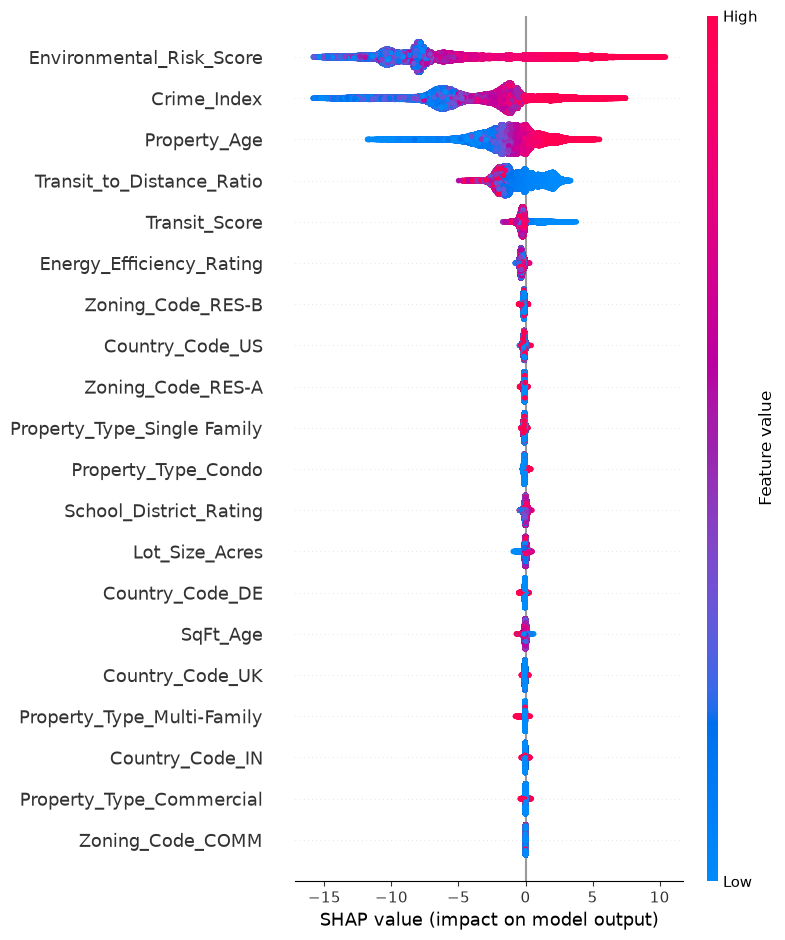

In [74]:
# Global SHAP summary plot
shap.summary_plot(shap_values_positive,X_test_clf,show=True)

- Positive SHAP value → pushes the prediction toward Is_risk / class 1.
- Negative SHAP value → pushes the prediction toward Non-Is_risk / class 0.
- Larger absolute SHAP values → stronger influence on the prediction.

###  Generate and save the SHAP summary plot as shap_summary_clf.png.

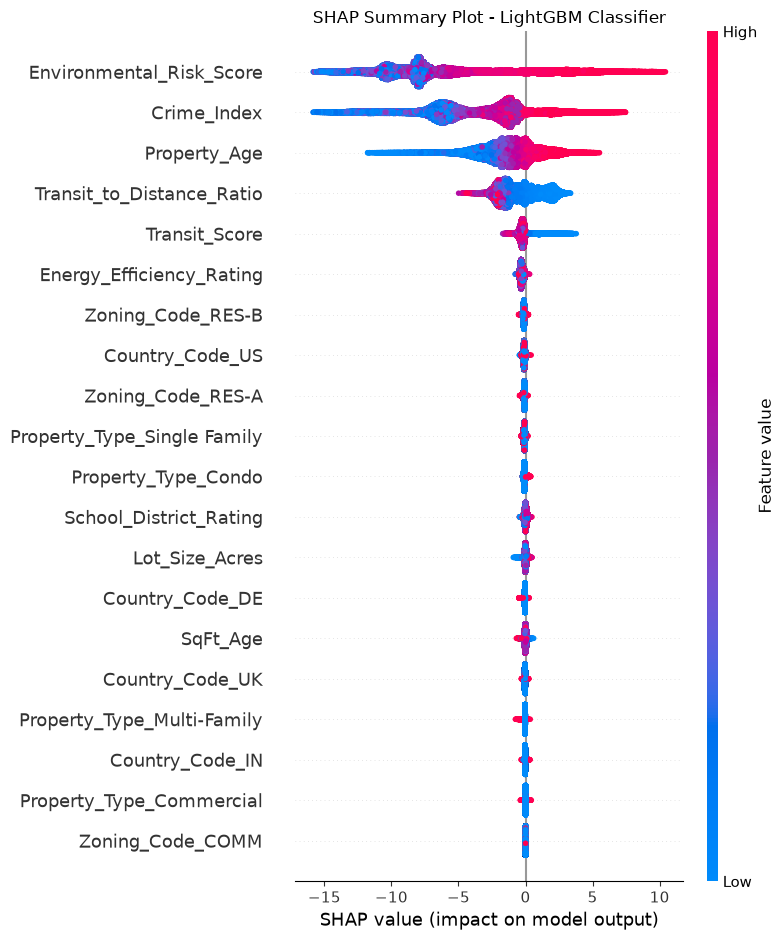

In [75]:
# Generate SHAP summary plot
shap.summary_plot( shap_values,X_test_clf,show=False)
plt.title("SHAP Summary Plot - LightGBM Classifier")
plt.tight_layout()
plt.savefig("lightgbm_shap_summary.png",dpi=300,bbox_inches="tight")
plt.show()

###  Pick one specific row from the test set (a High Risk property) and generate a SHAP force plot explaining exactly why the model flagged it.

In [76]:
y_test_proba = final_lgbm.predict_proba(X_test_clf)[:, 1]

# Find the highest-risk property
high_risk_idx = np.argmax(y_test_proba)

In [78]:
print("High-Risk Row Index:", high_risk_idx)
print("Is_risk Probability:", y_test_proba[high_risk_idx])

High-Risk Row Index: 73170
Is_risk Probability: 0.999999999249211


In [79]:
X_high_risk = X_test_clf.iloc[high_risk_idx]
high_risk_shap = shap_values_positive[high_risk_idx]

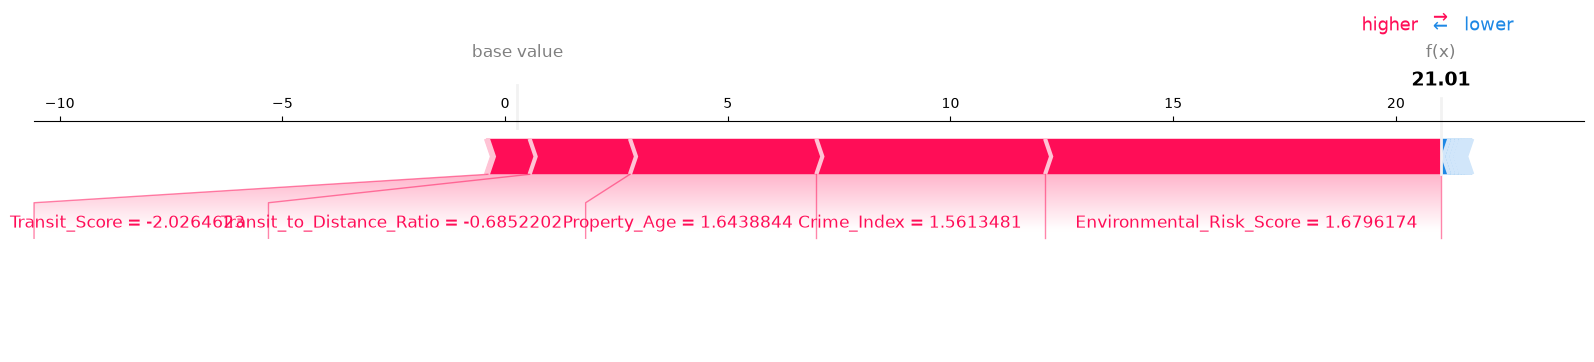

In [89]:
expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[1]

shap.force_plot(expected_value, high_risk_shap, X_high_risk,matplotlib = True)
plt.show()

- The SHAP force plot shows a raw model output of f(x) = 21, which corresponds to an almost 100% Is_risk probability after applying the sigmoid transformation. This indicates that the combined effect of the key features strongly pushed the prediction toward the High-Risk class.
- The positive SHAP contributions represent the features that increased the  is_risk, while negative contributions reduced it.

### Save the fully optimized LightGBM Classifier as final_lgbm_classifier.pkl.

In [87]:
joblib.dump(final_lgbm, "final_lgbm_classifier.pkl")

['final_lgbm_classifier.pkl']

###  Document all hyperparameter settings and final metrics in a JSON file model_metrics.json.

In [90]:
import json

In [93]:
model_metrics = {
    "models": {
        "xgboost_regressor": {
            "model_type": "XGBRegressor",

            "grid_search_cv": {
                "method": "GridSearchCV",
                "cv": 3,
                "best_parameters": {
                    "learning_rate": 0.05,
                    "max_depth": 9,
                    "n_estimators": 500,
                    "subsample": 0.7
                }
            },

            "optuna": {
                "method": "Optuna",
                "optimization_metric": "RMSE",
                "direction": "minimize",
                "best_parameters": {
                    "learning_rate": 0.08443759957758853,
                    "max_depth": 5,
                    "n_estimators": 900,
                    "subsample": 0.7255292163528891,
                    "colsample_bytree": 0.8502238815761733,
                    "min_child_weight": 5,
                    "gamma": 2.4595094762815597,
                    "reg_alpha": 1.8517860573342013,
                    "reg_lambda": 1.9516098959591434e-05
                }
            },

            "final_performance": {
                "MAE": 224315.3130,
                "RMSE": 352983.3393,
                "R2": 0.9190
            }
        },

        "lightgbm_classifier": {
            "model_type": "LGBMClassifier",

            "optuna": {
                "method": "Optuna",
                "optimization_metric": "ROC-AUC",
                "direction": "maximize",

                "best_trial": {
                    "best_ROC_AUC": 0.998463,

                    "best_parameters": {
                        "n_estimators": 226,
                        "learning_rate": 0.1876515219594504,
                        "num_leaves": 50,
                        "max_depth": 12,
                        "min_child_samples": 99,
                        "subsample": 0.8122683417265191,
                        "colsample_bytree": 0.9985227678484148,
                        "reg_alpha": 1.1439643308247125e-08,
                        "reg_lambda": 5.490373413931448
                    }
                }
            },

            "final_model_parameters": {
                "boosting_type": "gbdt",
                "class_weight": None,
                "colsample_bytree": 0.9985227678484148,
                "importance_type": "split",
                "learning_rate": 0.1876515219594504,
                "max_depth": 12,
                "min_child_samples": 99,
                "min_child_weight": 0.001,
                "min_split_gain": 0.0,
                "n_estimators": 226,
                "n_jobs": -1,
                "num_leaves": 50,
                "objective": "binary",
                "random_state": 42,
                "reg_alpha": 1.1439643308247125e-08,
                "reg_lambda": 5.490373413931448,
                "subsample": 0.8122683417265191,
                "subsample_for_bin": 200000,
                "subsample_freq": 0,
                "verbosity": -1
            },

            "final_performance": {
                "test_ROC_AUC": 0.998463
            }
        }
    }
}

In [94]:
with open("model_metrics.json", "w") as f:
    json.dump(model_metrics, f, indent=4)
    print(json.dumps(model_metrics, indent=4))
    print("\nmodel_metrics.json saved successfully!")
    

{
    "models": {
        "xgboost_regressor": {
            "model_type": "XGBRegressor",
            "grid_search_cv": {
                "method": "GridSearchCV",
                "cv": 3,
                "best_parameters": {
                    "learning_rate": 0.05,
                    "max_depth": 9,
                    "n_estimators": 500,
                    "subsample": 0.7
                }
            },
            "optuna": {
                "method": "Optuna",
                "optimization_metric": "RMSE",
                "direction": "minimize",
                "best_parameters": {
                    "learning_rate": 0.08443759957758853,
                    "max_depth": 5,
                    "n_estimators": 900,
                    "subsample": 0.7255292163528891,
                    "colsample_bytree": 0.8502238815761733,
                    "min_child_weight": 5,
                    "gamma": 2.4595094762815597,
                    "reg_alpha": 1.8517860573342013,
     